<a href="https://colab.research.google.com/github/rugvedchauragade/MRI-TUMOR-DETECTION-MODEL/blob/main/modeltraining.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
!pip install tensorflow pillow numpy scikit-learn matplotlib seaborn flask

In [ ]:
import os # for directory and file operations
import numpy as np #for numerical operations and handling image arrays
import random # for generating random values for augmentation
from PIL import Image, ImageEnhance #for image processing and enhancement

#keras
from tensorflow.keras.models import Sequential  # need it for neural network for making layer
from tensorflow.keras.layers import Input , Dense , Flatten ,Dropout # for model layers
from tensorflow.keras.preprocessing.image import load_img # for loading image
from tensorflow.keras.optimizers import Adam # for optimizer
from tensorflow.keras.applications import VGG16 # for using VGG16 model
from sklearn.utils import shuffle # for shuffling the data


In [ ]:
!unzip -q dataset.zip

replace MRI images/Testing/glioma/Te-gl_1.jpg? [y]es, [n]o, [A]ll, [N]one, [r]ename: 

In [ ]:
import os
from sklearn.utils import shuffle

train_dir = 'Training'
test_dir = 'Testing'

if not os.path.exists(train_dir):
  for root , dirs , files in os.walk('.'):
    if 'Training' in dirs:
      train_dir = os.path.join(root , 'Training')
      test_dir = os.path.join(root, 'Testing')
      break

if not os.path.exists(train_dir) and os.path.exists('/Training'):
  train_dir = '/Training'
  test_dir = '/Testing'

print(f"Found Training at : {train_dir}")
print(f"Found Testing at : {test_dir}")

train_paths = []
train_labels = []
test_paths = []
test_labels = []
# kya code dekh raha hai mene hi likha hai ai ne nhiiii
#collect training image paths and labels
for label in os.listdir(train_dir):
  sub_folder = os.path.join(train_dir, label)
  if os.path.isdir(sub_folder):
    for img in os.listdir(sub_folder):
      train_paths.append(os.path.join(sub_folder, img))
      train_labels.append(label)

#collect testing image paths and labels
for label in os.listdir(test_dir):
  sub_folder = os.path.join(test_dir, label)
  if os.path.isdir(sub_folder):
    for img in os.listdir(sub_folder):
      test_paths.append(os.path.join(sub_folder, img))
      test_labels.append(label)

# shuffle datset
train_paths ,train_labels = shuffle(train_paths, train_labels ,random_state = 42)
test_paths , test_labels = shuffle(test_paths, test_labels ,random_state = 42)

print(f"Total Training Samples : {len(train_paths)} ")
print(f"Total Testing Samples : {len(test_paths)} ")



Found Training at : ./MRI images/Training
Found Testing at : ./MRI images/Testing
Total Training Samples : 5600 
Total Testing Samples : 1600 


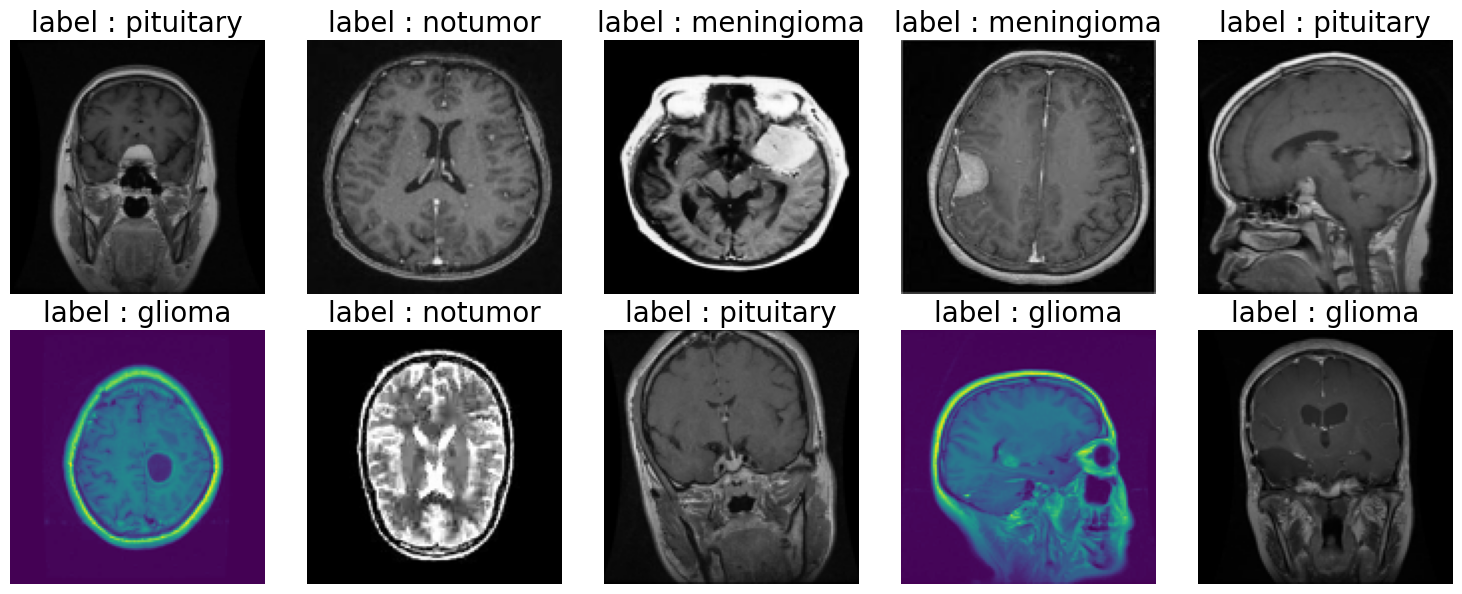

In [ ]:
import random
import matplotlib.pyplot as plt

# select random indicies for 10 images
random_indices = random.sample(range(len(train_paths)) , 10)
random_indices

# create a figure to display images in 2rows
fig , axes = plt.subplots(2,5 , figsize = (15,6))
axes = axes.ravel()

# loop through the random indices and display images
for i , idx in enumerate(random_indices):
  img_paths = train_paths[idx]
  img = Image.open(img_paths)
  img = img.resize((128,128))

  # display image
  axes[i].imshow(img)
  axes[i].axis("off")
  axes[i].set_title(f"label : {train_labels[idx]}" , fontsize = 20)

plt.tight_layout()
plt.show()




In [ ]:
import os # for directory and file operations
import numpy as np #for numerical operations and handling image arrays
import random # for generating random values for augmentation
from PIL import Image, ImageEnhance #for image processing and enhancement

#keras
from tensorflow.keras.models import Sequential  # need it for neural network for making layer
from tensorflow.keras.layers import Input , Dense , Flatten ,Dropout # for model layers
from tensorflow.keras.preprocessing.image import load_img # for loading image
from tensorflow.keras.optimizers import Adam # for optimizer
from tensorflow.keras.applications import VGG16 # for using VGG16 model
from sklearn.utils import shuffle # for shuffling the data

# PATH AND SETUP
train_dir = 'Training'
test_dir = 'Testing'

# if dataset was unzipped inside a subfolder
# bha comments bhi mene like hai
# pura code mene likha hai

if not os.path.exists(train_dir):
  for root , dirs , files in os.walk('.'):
    if 'Training' in dirs :
      train_dir = os.path.join(root , 'Training')
      test_dir = os.path.join(root , 'Testing')
      break

IMAGE_SIZE = 128

#collect training image paths and labels
train_paths = []
train_labels = []

for label in os.listdir(train_dir):
  sub_folder = os.path.join(train_dir , label)
  if os.path.isdir(sub_folder):
    for img in os.listdir(sub_folder):
      train_paths.append(os.path.join(sub_folder , img))
      train_labels.append(label)

train_paths , train_labels = shuffle(train_paths , train_labels , random_state = 42)

print(f"Total Training Samples : {len(train_paths)}")

# 2. image augmentation
def augment_image(image):
  image = Image.fromarray(np.uint8(image))
  image = ImageEnhance.Brightness(image).enhance(random.uniform(0.8 , 1.2))
  image = ImageEnhance.Contrast(image).enhance(random.uniform(0.8 , 1.2))
  image =  np.array(image)/255.0
  return image

# helper function
def open_images(paths):
  images = []
  for path in paths :
    img = load_img(path , target_size = (IMAGE_SIZE , IMAGE_SIZE))
    img = augment_image(img)
    images.append(img)
  return np.array(images)

def encode_labels(labels):
  unique_labels = sorted(os.listdir(train_dir))
  encoded = [unique_labels.index(label) for label in labels]
  return np.array(encoded)

def datagen(paths, labels , batch_size = 12 , epochs = 1):
  for _ in range (epochs):
    for i in range (0 , len(paths) , batch_size):
      batch_paths = paths[i:i+batch_size]
      batch_labels = labels[i:i+batch_size]

      batch_images = open_images(batch_paths)
      batch_encoded_labels = encode_labels(batch_labels)

      yield batch_images , batch_encoded_labels


# Vgg16 modelarchitecture
base_model = VGG16(input_shape = (IMAGE_SIZE , IMAGE_SIZE , 3),include_top = False ,weights= 'imagenet' )

for layer in base_model.layers:
  layer.trainable = False

base_model.layers[-2].trainable = True
base_model.layers[-3].trainable = True
base_model.layers[-4].trainable = True

num_classes = len(os.listdir(train_dir))

model = Sequential([
    Input( shape = (IMAGE_SIZE , IMAGE_SIZE , 3)),
    base_model,
    Flatten(),
    Dense(128, activation = 'relu'),
    Dropout(0.2),
    Dense(num_classes , activation = 'softmax')
])

# COMPILE AND TRAIN
model.compile(
    optimizer = Adam(learning_rate = 0.0001),
    loss = 'sparse_categorical_crossentropy',
    metrics = ['sparse_categorical_accuracy']
)

batch_size = 20
steps = int(len(train_paths) / batch_size)
epochs = 5

print("Strating Training ...")
history = model.fit(
    datagen(train_paths , train_labels , batch_size=batch_size , epochs=epochs),
    steps_per_epoch = steps,
    epochs= epochs
)

# save the  trained model
model.save('brain_tumor_vgg16_model.h5')
print("Model saved successfully as 'brain_tumor_vgg16_model.h5'!")


Total Training Samples : 5600
Strating Training ...
Epoch 1/5
280/280 ━━━━━━━━━━━━━━━━━━━━ 26s 67ms/step - loss: 0.4351 - sparse_categorical_accuracy: 0.8352
Epoch 2/5
280/280 ━━━━━━━━━━━━━━━━━━━━ 19s 67ms/step - loss: 0.2298 - sparse_categorical_accuracy: 0.9121
Epoch 3/5
280/280 ━━━━━━━━━━━━━━━━━━━━ 19s 67ms/step - loss: 0.1651 - sparse_categorical_accuracy: 0.9386
Epoch 4/5
280/280 ━━━━━━━━━━━━━━━━━━━━ 19s 67ms/step - loss: 0.1011 - sparse_categorical_accuracy: 0.9605
Epoch 5/5
280/280 ━━━━━━━━━━━━━━━━━━━━ 19s 67ms/step - loss: 0.0792 - sparse_categorical_accuracy: 0.9709


Model saved successfully as 'brain_tumor_vgg16_model.h5'!


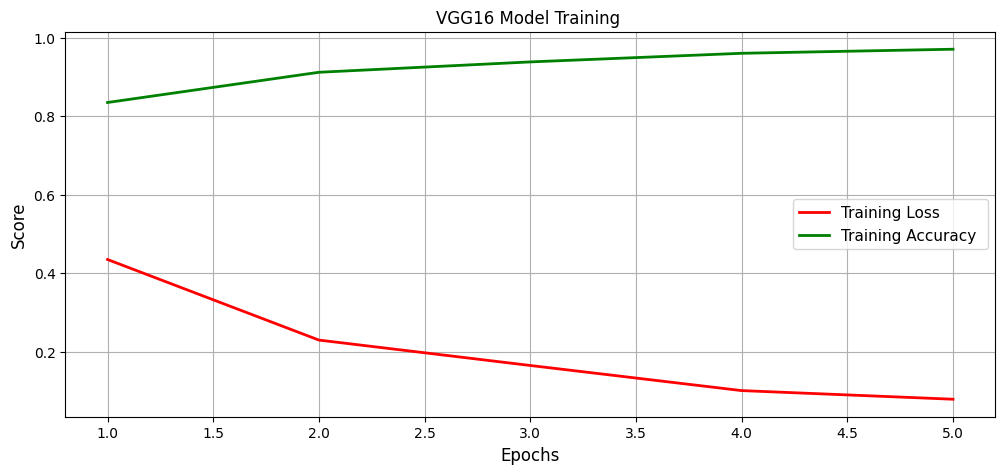

In [ ]:
import matplotlib.pyplot as plt

# set up figure
plt.figure(figsize = (12,5))
plt.grid(True)

# exact loss and accuracy metrices from training history
acc_key = 'sparse_categorical_accuracy' if 'sparse_categorical_accuracy' in history.history else 'accuracy'
loss = history.history['loss']
acc = history.history[acc_key]
epochs_range = range(1, len(loss) + 1)

# plot loss
plt.plot(epochs_range, loss , 'r-' , linewidth = 2 , label = 'Training Loss')

#plot accuracy
plt.plot(epochs_range , acc, 'g-' ,linewidth = 2 , label = 'Training Accuracy ')

plt.title('VGG16 Model Training ')
plt.xlabel('Epochs' , fontsize =12)
plt.ylabel('Score' , fontsize = 12)
plt.legend(loc = 'center right' , fontsize = 11)
plt.show()

50/50 ━━━━━━━━━━━━━━━━━━━━ 4s 41ms/step

--Classification Report--
              precision    recall  f1-score   support

      glioma       0.99      0.73      0.84       400
  meningioma       0.79      0.90      0.84       400
     notumor       0.96      0.95      0.96       400
   pituitary       0.88      0.99      0.93       400

    accuracy                           0.89      1600
   macro avg       0.90      0.89      0.89      1600
weighted avg       0.90      0.89      0.89      1600



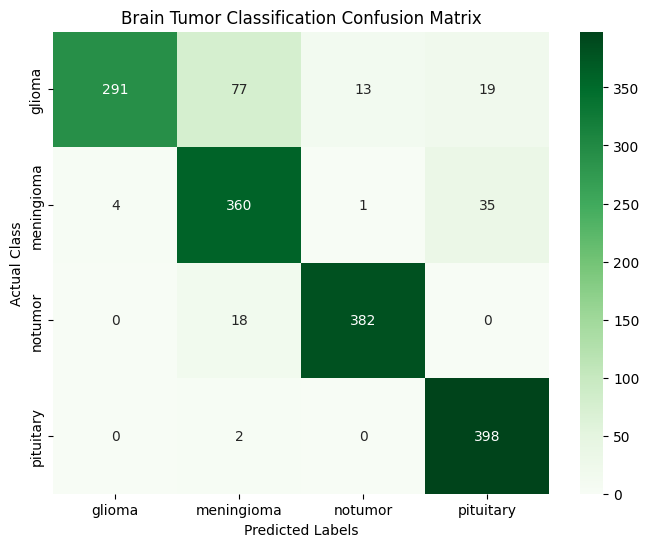

In [ ]:
import os
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt
from sklearn.metrics import classification_report , confusion_matrix
from tensorflow.keras.preprocessing.image import load_img , img_to_array

# locate testing directory
test_dir = 'Testing'
if not os.path.exists(test_dir):
  for root , dirs , files in os.walk('.'):
    if 'Testing' in dirs:
      test_dir = os.path.join(root , 'Testing')
      break

class_names = sorted(os.listdir(train_dir))

# collect and preprocess test set images
test_images = []
test_labels = []

for label in class_names :
  sub_folder = os.path.join(test_dir , label)
  if os.path.isdir(sub_folder):
    for img_name in os.listdir(sub_folder):
      img_path = os.path.join(sub_folder , img_name)
      img = load_img(img_path , target_size=(128 , 128))
      img_arr = img_to_array(img) / 255.0
      test_images.append(img_arr)
      test_labels.append(class_names.index(label))

X_test = np.array(test_images)
y_test = np.array(test_labels)

# make predictions on test set
predictions = model.predict(X_test)
y_pred = np.argmax(predictions , axis= 1)

# haa bhai pura code mene hi likaha hai
#print classification report
print("\n--Classification Report--")
print(classification_report(y_test , y_pred , target_names = class_names))

# plot confusion matrixxx
cm = confusion_matrix(y_test , y_pred)
plt.figure(figsize = (8,6))
sns.heatmap(cm, annot= True , fmt = 'd' , cmap = 'Greens' ,
            xticklabels = class_names , yticklabels = class_names)

plt.title('Brain Tumor Classification Confusion Matrix')
plt.xlabel('Predicted Labels')
plt.ylabel('Actual Class')
plt.show()


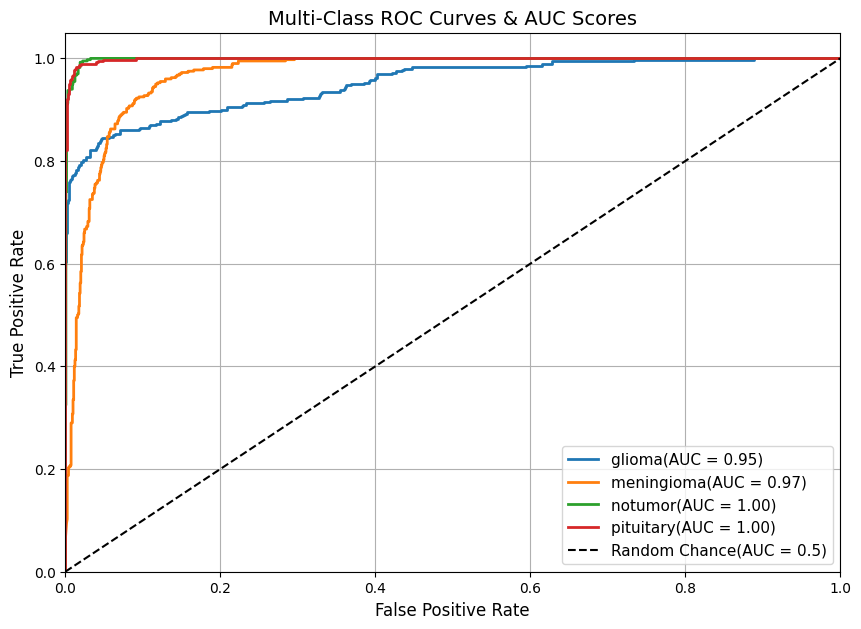

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.metrics import roc_curve ,auc
from sklearn.preprocessing import label_binarize

# binarize test labels for multi class roc computation
y_test_bin =label_binarize(y_test , classes = list(range(len(class_names))))

#plot roc curve for each tumor class
plt.figure(figsize = (10 , 7))

for i , class_name in enumerate(class_names):

  fpr , tpr , _ = roc_curve(y_test_bin[:,i] , predictions[:,i])
  roc_auc = auc(fpr , tpr)
  plt.plot(fpr , tpr , linewidth = 2 , label = f'{class_name}(AUC = {roc_auc:.2f})')

# reference line for making random guessing
plt.plot([0,1] , [0,1] , 'k--' ,linewidth = 1.5 , label = 'Random Chance(AUC = 0.5)')

plt.xlim([0.0 , 1.0])
plt.ylim([0.0 ,1.05])
plt.xlabel('False Positive Rate' , fontsize = 12)
plt.ylabel('True Positive Rate' , fontsize = 12)
plt.title('Multi-Class ROC Curves & AUC Scores' , fontsize = 14)
plt.legend(loc = 'lower right' , fontsize = 11)
plt.grid(True)
plt.show()



Please upload a brain MRI image file from your computer :


Saving Tr-aug-me_91.jpg to Tr-aug-me_91.jpg
1/1 ━━━━━━━━━━━━━━━━━━━━ 2s 2s/step


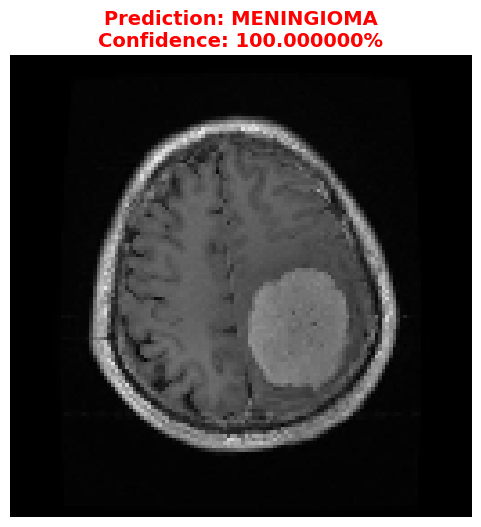


--- Diagnostic Probability Breakdown ---
Glioma      :   0.00%
Meningioma  : 100.00%
Notumor     :   0.00%
Pituitary   :   0.00%


In [ ]:
import numpy as np
import matplotlib.pyplot as plt
from google.colab import files
from tensorflow.keras.preprocessing.image import load_img , img_to_array
from tensorflow.keras.models import load_model

# load the trained model
model = load_model('brain_tumor_vgg16_model.h5')
class_names = ['glioma', 'meningioma' , 'notumor' ,'pituitary']

# trigger goggle colab file upload prompt
print("Please upload a brain MRI image file from your computer :")
uploaded = files.upload()

for file_name in uploaded.keys():
  #preprocess image to match vgg16 input dimension (128x128, normalized)
  img = load_img(file_name , target_size = (128 , 128))
  img_array = img_to_array(img) / 255.0
  img_batch = np.expand_dims(img_array , axis = 0)

  # generate model prediction
  predictions = model.predict(img_batch)[0]
  predicted_idx = np.argmax(predictions)
  predicted_class = class_names[predicted_idx]
  confidence = predictions[predicted_idx] * 100

  # display the mri scan with prediction outcome
  plt.figure(figsize=(6,6))
  plt.imshow(img)
  plt.axis('off')
  title_color = 'green' if predicted_class == 'notumor' else 'red'
  plt.title(f"Prediction: {predicted_class.upper()}\nConfidence: {confidence:2f}%",
            fontsize=14 ,color = title_color , fontweight = 'bold')
  plt.show()

#print class probablity breakdown
print("\n--- Diagnostic Probability Breakdown ---")
for name , prob in zip(class_names , predictions):
  print(f"{name.capitalize():<12}: {prob * 100:6.2f}%")
